# Figure 4 — publication plotting

This notebook reads only validated tables written by the analysis notebook.
Panels A–E are exported individually and assembled into a publication-scale
figure. The one-region analysis is not repeated because it is already shown in
Figure 1E.


In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd

PROJECT_ROOT = Path(
    os.environ.get("MITOXY_PROJECT_ROOT", "/scratch/ar58064/mitoxy")
).resolve()
REFERENCE_DIR = PROJECT_ROOT / "data" / "reference" / "figure_4"
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "figure_4_clean"
FIGURE_DIR = PROJECT_ROOT / "figures" / "figure_4_clean"
for directory in [REFERENCE_DIR, OUTPUT_DIR, FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyBboxPatch, FancyArrowPatch
from matplotlib.ticker import MultipleLocator
from PIL import Image as PILImage, ImageChops

BLUE = "#087EBD"
ORANGE = "#E36A00"
TEAL = "#00A67E"
PURPLE = "#8053A6"
DARK = "#202832"
MID = "#667386"
GRID = "#DDE3E9"
BAND = "#F2F5F8"
WHITE = "#FFFFFF"

mpl.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 13,
    "axes.labelcolor": DARK, "text.color": DARK,
    "xtick.color": "#4E5968", "ytick.color": DARK,
    "axes.linewidth": 1.1, "figure.facecolor": WHITE,
    "axes.facecolor": WHITE, "savefig.facecolor": WHITE,
    "svg.fonttype": "none", "pdf.fonttype": 42,
})

def p_text(value):
    return f"{value:.1e}" if value < 0.001 else f"{value:.3f}"

def panel_letter(fig, letter):
    fig.text(0.025, 0.965, letter, fontsize=34, fontweight="bold",
             color=DARK, ha="left", va="top")

def clean_axes(ax, grid="x"):
    ax.grid(axis=grid, color=GRID, linewidth=1)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_color("#8B96A3")
    ax.spines["bottom"].set_color("#8B96A3")

def save_panel(fig, stem):
    paths = {}
    for suffix in ["png", "svg", "pdf"]:
        path = FIGURE_DIR / f"{stem}.{suffix}"
        fig.savefig(path, dpi=400, bbox_inches="tight", pad_inches=0.12)
        paths[suffix] = path
    return paths

def read_panel(stem):
    path = OUTPUT_DIR / stem
    if not path.exists():
        raise FileNotFoundError(
            f"Missing {path}. Run 01_Figure4_Analysis.ipynb first."
        )
    return pd.read_csv(path)

panel_b = read_panel("panel_b_region_scores.csv")
patient_summary = read_panel("panel_b_patient_summary.csv")
panel_c = read_panel("panel_c_variance_partition.csv")
panel_d = read_panel("panel_d_punctuated_models.csv")
panel_e = read_panel("panel_e_ith_robustness.csv")


Project root: /scratch/ar58064/mitoxy


## Panel A — multiregion design


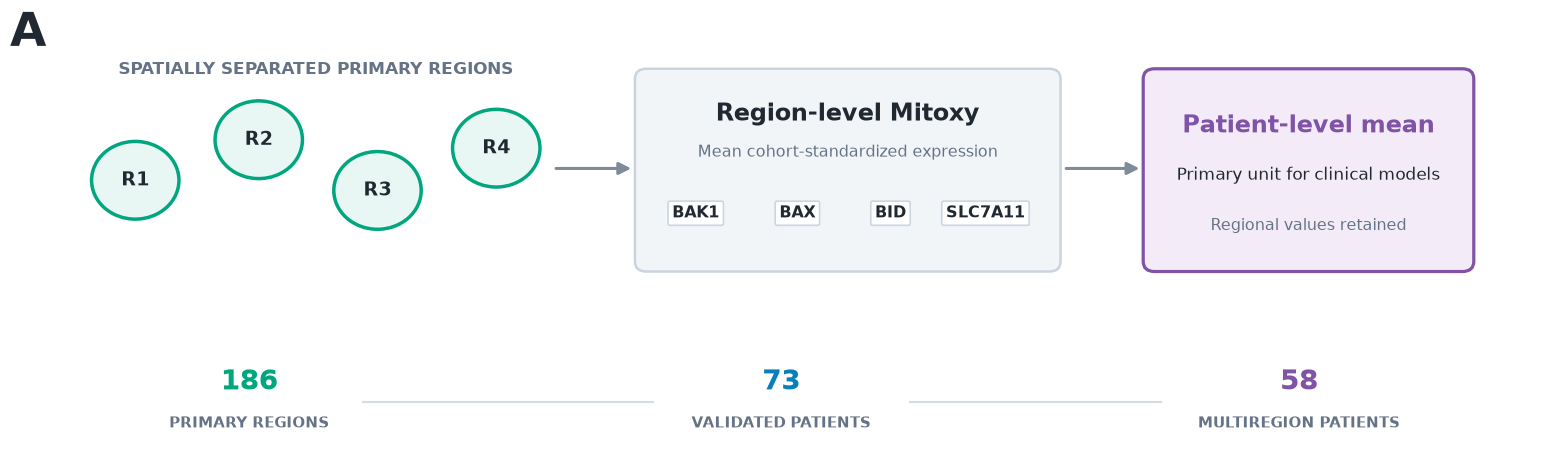

In [2]:
fig, ax = plt.subplots(figsize=(16.0, 4.8))
ax.set_xlim(0, 16)
ax.set_ylim(0, 5)
ax.axis("off")

region_xy = [(1.15, 3.24), (2.45, 3.72), (3.70, 3.12), (4.95, 3.62)]
for i, (x, y) in enumerate(region_xy, start=1):
    circle = Circle((x, y), 0.46, facecolor="#E8F7F3", edgecolor=TEAL,
                    linewidth=2.5)
    ax.add_patch(circle)
    ax.text(x, y, f"R{i}", ha="center", va="center",
            fontsize=14, fontweight="bold", color=DARK)

ax.text(3.05, 4.55, "SPATIALLY SEPARATED PRIMARY REGIONS",
        ha="center", va="center", fontsize=12.2, fontweight="bold", color=MID)
ax.add_patch(FancyArrowPatch(
    (5.55, 3.38), (6.40, 3.38), arrowstyle="-|>", mutation_scale=18,
    linewidth=2.2, color="#7F8B99",
))
box = FancyBboxPatch(
    (6.45, 2.20), 4.40, 2.32,
    boxstyle="round,pad=0.04,rounding_size=0.12",
    facecolor="#F2F5F8", edgecolor="#C9D4DE", linewidth=1.8,
)
ax.add_patch(box)
ax.text(8.65, 4.02, "Region-level Mitoxy", ha="center", va="center",
        fontsize=17, fontweight="bold", color=DARK)
ax.text(8.65, 3.57, "Mean cohort-standardized expression",
        ha="center", va="center", fontsize=11.8, color=MID)

gene_x = [7.05, 8.12, 9.10, 10.10]
for x, gene in zip(gene_x, ["BAK1", "BAX", "BID", "SLC7A11"]):
    ax.text(x, 2.85, gene, ha="center", va="center", fontsize=11.2,
            fontweight="bold", color=DARK,
            bbox={"boxstyle":"round,pad=0.27,rounding_size=0.12",
                  "facecolor":WHITE, "edgecolor":"#CBD6E0", "linewidth":1.2})

ax.add_patch(FancyArrowPatch(
    (10.92, 3.38), (11.75, 3.38), arrowstyle="-|>", mutation_scale=18,
    linewidth=2.2, color="#7F8B99",
))
patient_box = FancyBboxPatch(
    (11.80, 2.20), 3.40, 2.32,
    boxstyle="round,pad=0.04,rounding_size=0.12",
    facecolor="#F3ECF8", edgecolor=PURPLE, linewidth=2.3,
)
ax.add_patch(patient_box)
ax.text(13.50, 3.88, "Patient-level mean", ha="center", va="center",
        fontsize=17, fontweight="bold", color=PURPLE)
ax.text(13.50, 3.30, "Primary unit for clinical models",
        ha="center", va="center", fontsize=12.0, color=DARK)
ax.text(13.50, 2.70, "Regional values retained",
        ha="center", va="center", fontsize=11.5, color=MID)

badge_specs = [
    (2.35, "186", "PRIMARY REGIONS", TEAL),
    (7.95, "73", "VALIDATED PATIENTS", BLUE),
    (13.40, "58", "MULTIREGION PATIENTS", PURPLE),
]
for x, value, label, color in badge_specs:
    ax.text(x, 0.85, value, ha="center", va="center", fontsize=20,
            fontweight="bold", color=color)
    ax.text(x, 0.36, label, ha="center", va="center", fontsize=10.6,
            fontweight="bold", color=MID)
for x1, x2 in [(3.55, 6.60), (9.30, 11.95)]:
    ax.plot([x1, x2], [0.62, 0.62], color="#D5DCE3", linewidth=1.5)

panel_letter(fig, "A")
fig.subplots_adjust(left=0.035, right=0.985, top=0.92, bottom=0.04)
panel_a_paths = save_panel(fig, "figure_4a_multiregion_design")
plt.show()


## Panel B — patient and regional variation


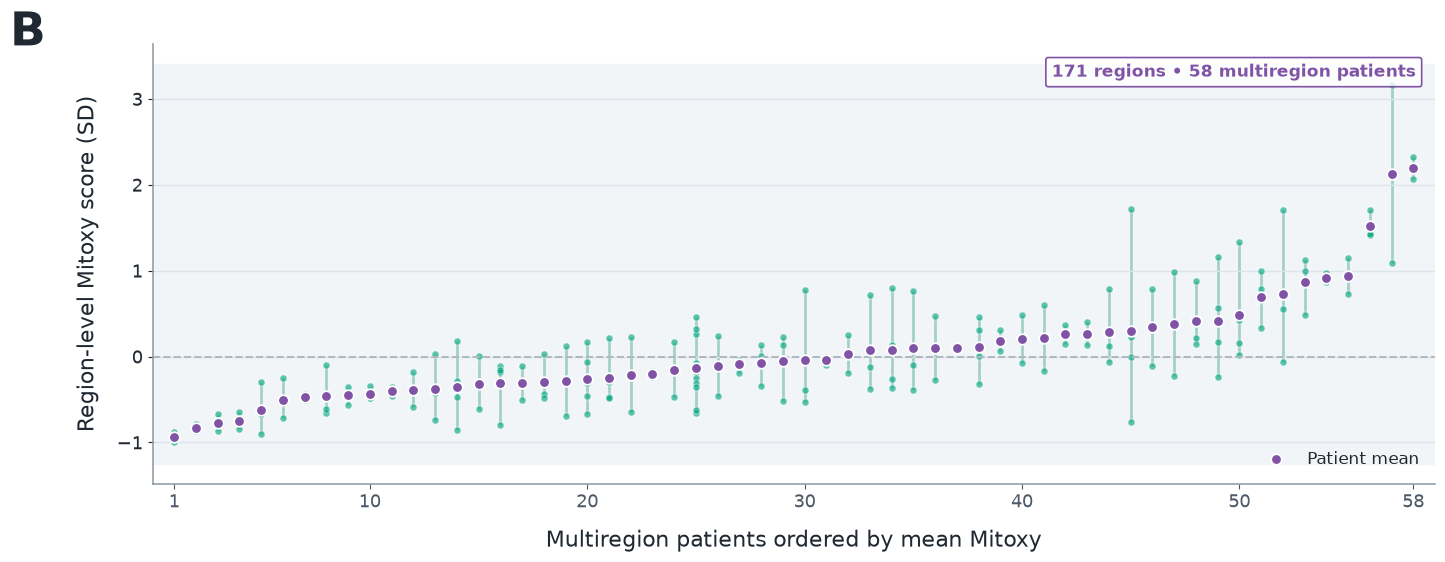

In [3]:
fig, ax = plt.subplots(figsize=(15.0, 6.2))
ax.axhspan(panel_b["mitoxy"].min() - 0.25,
           panel_b["mitoxy"].max() + 0.25, color=BAND, zorder=0)

for row in patient_summary.itertuples(index=False):
    ax.vlines(row.patient_order, row.patient_min, row.patient_max,
              color="#9FCFC3", linewidth=2.0, alpha=0.95, zorder=1)

ax.scatter(panel_b["patient_order"], panel_b["mitoxy"],
           s=26, color=TEAL, alpha=0.62, edgecolor=WHITE,
           linewidth=0.55, zorder=2)
ax.scatter(patient_summary["patient_order"], patient_summary["patient_mean"],
           s=58, color=PURPLE, edgecolor=WHITE, linewidth=1.25,
           zorder=3, label="Patient mean")

ax.axhline(0, color="#AEB8C2", linestyle="--", linewidth=1.4)
ax.set_xlim(0, 59)
ax.set_xticks([1, 10, 20, 30, 40, 50, 58])
ax.set_xlabel("Multiregion patients ordered by mean Mitoxy",
              fontsize=16, labelpad=13)
ax.set_ylabel("Region-level Mitoxy score (SD)", fontsize=16, labelpad=13)
ax.text(0.985, 0.955, "171 regions • 58 multiregion patients",
        transform=ax.transAxes, ha="right", va="top", fontsize=12.5,
        fontweight="bold", color=PURPLE,
        bbox={"boxstyle":"round,pad=0.34,rounding_size=0.13",
              "facecolor":(1,1,1,0.82), "edgecolor":PURPLE,
              "linewidth":1.2})
clean_axes(ax, "y")
ax.legend(frameon=False, loc="lower right", fontsize=12.5)
panel_letter(fig, "B")
fig.subplots_adjust(left=0.12, right=0.975, top=0.91, bottom=0.20)
panel_b_paths = save_panel(fig, "figure_4b_regional_variation")
plt.show()


## Panel C — variance partition


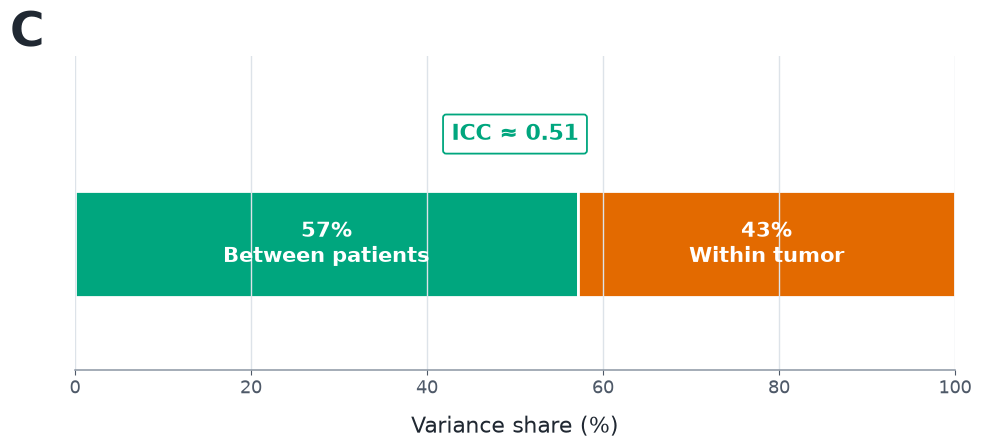

In [4]:
fig, ax = plt.subplots(figsize=(10.0, 4.9))
between = panel_c.loc[
    panel_c["component"].eq("Between patients"), "variance_percent"
].iloc[0]
within = panel_c.loc[
    panel_c["component"].eq("Within tumor"), "variance_percent"
].iloc[0]

ax.barh([0], [between], color=TEAL, height=0.46,
        edgecolor=WHITE, linewidth=2)
ax.barh([0], [within], left=[between], color=ORANGE, height=0.46,
        edgecolor=WHITE, linewidth=2)
ax.text(between / 2, 0, f"{between:.0f}%\nBetween patients",
        ha="center", va="center", fontsize=15, fontweight="bold", color=WHITE)
ax.text(between + within / 2, 0, f"{within:.0f}%\nWithin tumor",
        ha="center", va="center", fontsize=15, fontweight="bold", color=WHITE)
ax.text(50, 0.48, "ICC ≈ 0.51", ha="center", va="center",
        fontsize=16, fontweight="bold", color=TEAL,
        bbox={"boxstyle":"round,pad=0.38,rounding_size=0.14",
              "facecolor":(1,1,1,0.84), "edgecolor":TEAL,
              "linewidth":1.3})
ax.set_xlim(0, 100)
ax.set_ylim(-0.55, 0.82)
ax.set_yticks([])
ax.set_xlabel("Variance share (%)", fontsize=16, labelpad=13)
ax.xaxis.set_major_locator(MultipleLocator(20))
clean_axes(ax, "x")
ax.spines["left"].set_visible(False)
panel_letter(fig, "C")
fig.subplots_adjust(left=0.09, right=0.97, top=0.87, bottom=0.23)
panel_c_paths = save_panel(fig, "figure_4c_variance_partition")
plt.show()


## Panel D — adjusted punctuated-evolution contrast


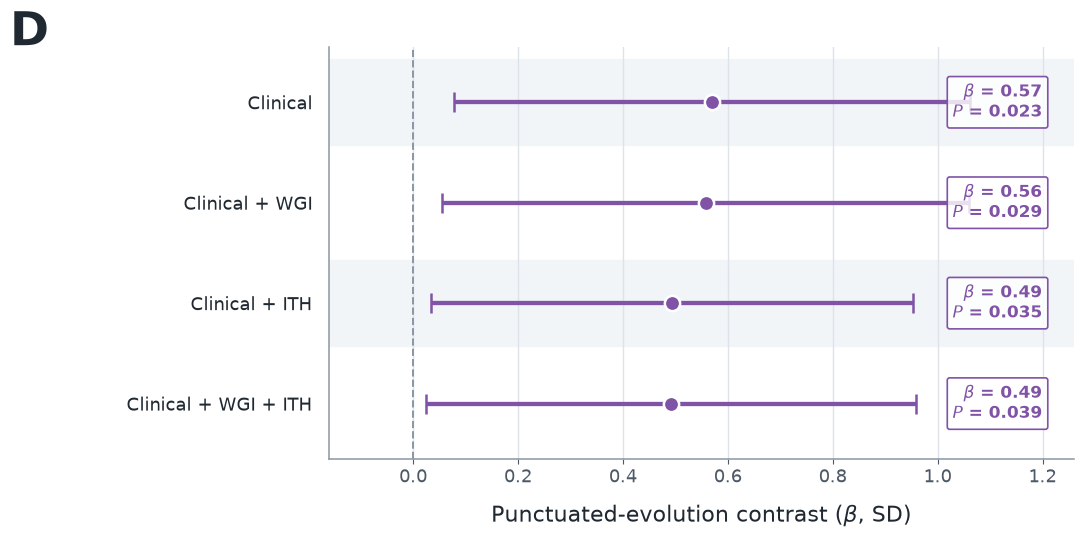

In [5]:
data = panel_d.iloc[::-1].reset_index(drop=True)
y = np.arange(len(data))
fig, ax = plt.subplots(figsize=(11.2, 5.8))
for i in range(len(data)):
    if i % 2 == 1:
        ax.axhspan(i - 0.43, i + 0.43, color=BAND, zorder=0)

for i, row in enumerate(data.itertuples(index=False)):
    ax.errorbar(row.beta, i,
                xerr=[[row.beta-row.ci_low], [row.ci_high-row.beta]],
                fmt="o", color=PURPLE, ecolor=PURPLE, markersize=11,
                elinewidth=3.1, capsize=7, capthick=2,
                markeredgecolor=WHITE, markeredgewidth=1.8, zorder=3)
    ax.text(1.20, i,
            rf"$\beta$ = {row.beta:.2f}" + "\n" + rf"$P$ = {p_text(row.p_value)}",
            ha="right", va="center", fontsize=12.2, fontweight="bold",
            color=PURPLE,
            bbox={"boxstyle":"round,pad=0.31,rounding_size=0.14",
                  "facecolor":(1,1,1,0.82), "edgecolor":PURPLE,
                  "linewidth":1.2})

ax.set_yticks(y, data["model"], fontsize=12.7)
ax.axvline(0, color="#8B96A3", linestyle="--", linewidth=1.4)
ax.set_xlim(-0.16, 1.26)
ax.set_ylim(-0.55, len(data)-0.45)
ax.set_xlabel(r"Punctuated-evolution contrast ($\beta$, SD)",
              fontsize=16, labelpad=13)
ax.tick_params(axis="y", length=0, pad=12)
clean_axes(ax, "x")
panel_letter(fig, "D")
fig.subplots_adjust(left=0.31, right=0.975, top=0.90, bottom=0.19)
panel_d_paths = save_panel(fig, "figure_4d_punctuated_adjustment")
plt.show()


## Panel E — ITH dispersion robustness


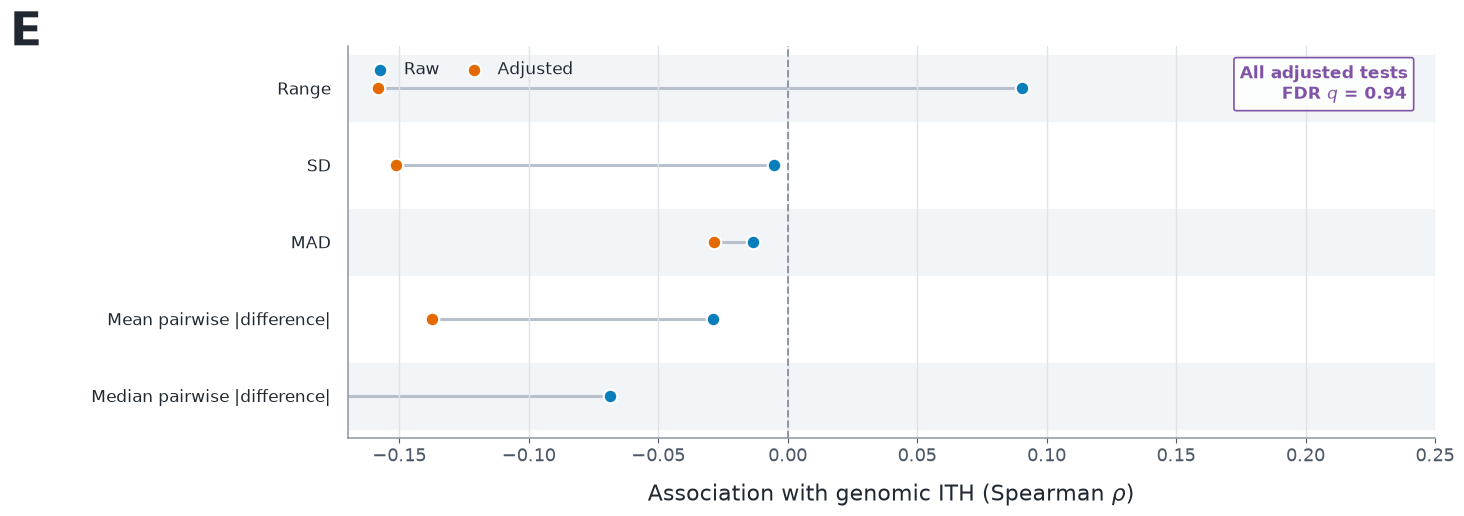

In [6]:
data = panel_e.iloc[::-1].reset_index(drop=True)
y = np.arange(len(data))
fig, ax = plt.subplots(figsize=(15.0, 5.6))
for i in range(len(data)):
    if i % 2 == 0:
        ax.axhspan(i - 0.43, i + 0.43, color=BAND, zorder=0)

for i, row in enumerate(data.itertuples(index=False)):
    ax.plot([row.rho_raw, row.partial_rho], [i, i], color="#B8C1CB",
            linewidth=2.2, zorder=1)
    ax.scatter(row.rho_raw, i, s=95, color=BLUE, edgecolor=WHITE,
               linewidth=1.5, zorder=3,
               label="Raw" if i == 0 else None)
    ax.scatter(row.partial_rho, i, s=95, color=ORANGE, edgecolor=WHITE,
               linewidth=1.5, zorder=3,
               label="Adjusted" if i == 0 else None)

ax.axvline(0, color="#8B96A3", linestyle="--", linewidth=1.4)
ax.set_yticks(y, data["dispersion_metric"], fontsize=12.1)
ax.set_xlim(-0.17, 0.25)
ax.set_ylim(-0.55, len(data)-0.45)
ax.set_xlabel(r"Association with genomic ITH (Spearman $\rho$)",
              fontsize=16, labelpad=13)
ax.tick_params(axis="y", length=0, pad=12)
ax.text(0.975, 0.955, "All adjusted tests\nFDR $q$ = 0.94",
        transform=ax.transAxes, ha="right", va="top", fontsize=12.4,
        fontweight="bold", color=PURPLE,
        bbox={"boxstyle":"round,pad=0.34,rounding_size=0.13",
              "facecolor":(1,1,1,0.82), "edgecolor":PURPLE,
              "linewidth":1.2})
ax.legend(frameon=False, loc="upper left", ncol=2, fontsize=12.3,
          handletextpad=0.4, columnspacing=1.0)
clean_axes(ax, "x")
panel_letter(fig, "E")
fig.subplots_adjust(left=0.25, right=0.975, top=0.90, bottom=0.20)
panel_e_paths = save_panel(fig, "figure_4e_ith_robustness")
plt.show()


## Assemble Figure 4


Saved:
/scratch/ar58064/mitoxy/figures/figure_4_clean/Figure_4_complete.png
/scratch/ar58064/mitoxy/figures/figure_4_clean/Figure_4_complete.tiff


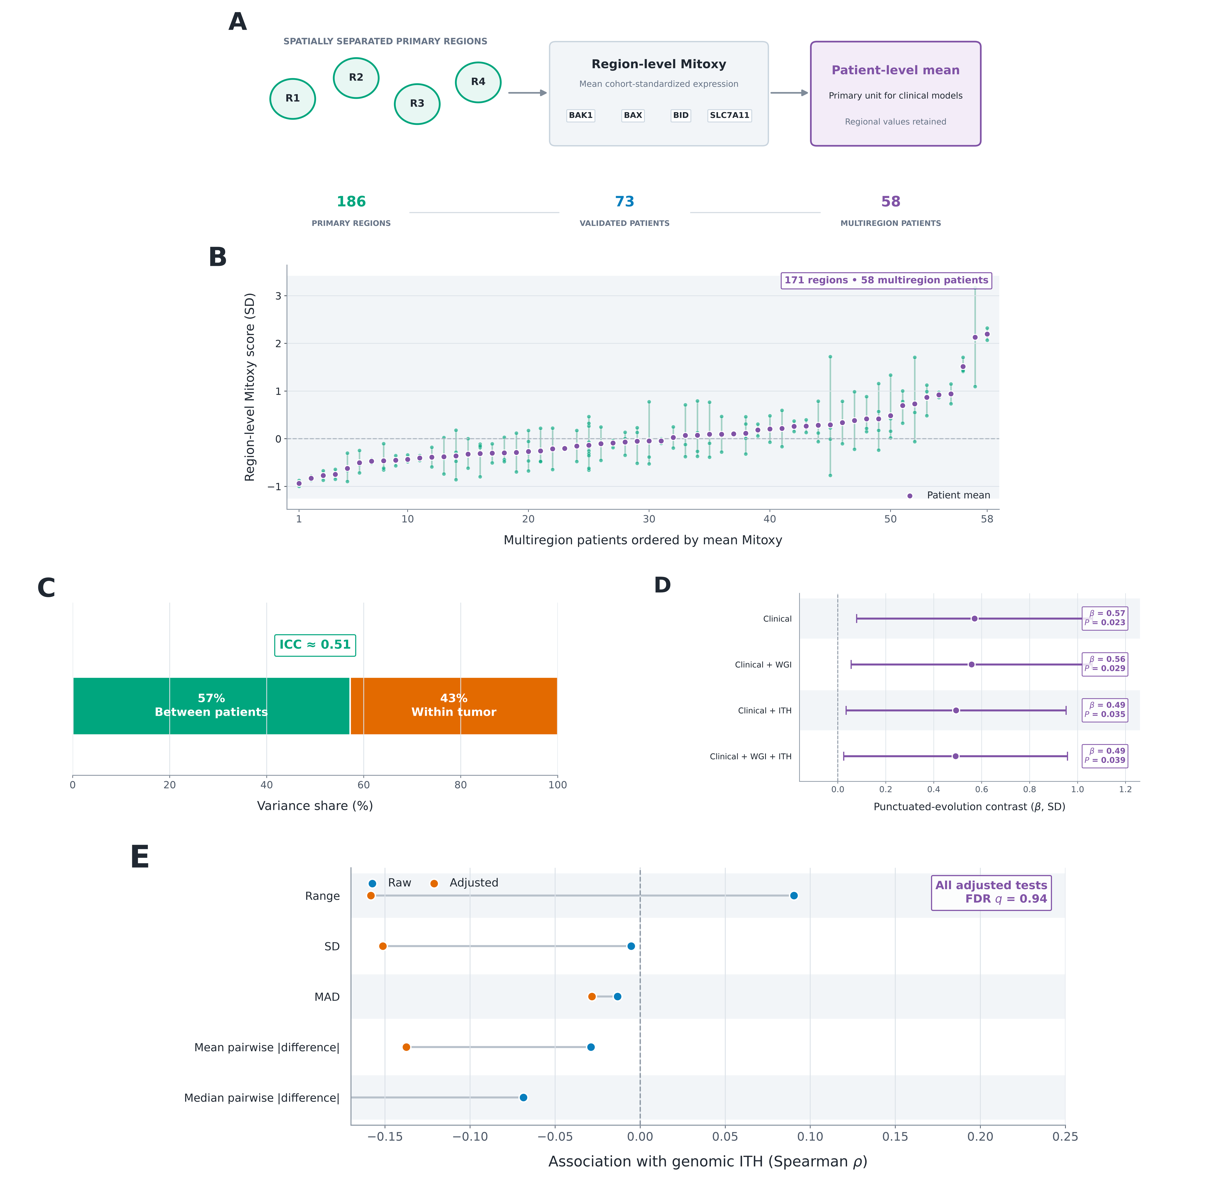

In [7]:
panel_paths = {
    "A": panel_a_paths["png"], "B": panel_b_paths["png"],
    "C": panel_c_paths["png"], "D": panel_d_paths["png"],
    "E": panel_e_paths["png"],
}

def trim_image(image, border=35):
    image = image.convert("RGB")
    background = PILImage.new("RGB", image.size, "white")
    box = ImageChops.difference(image, background).getbbox()
    if box is None:
        return image
    left, upper, right, lower = box
    return image.crop((
        max(0, left-border), max(0, upper-border),
        min(image.width, right+border), min(image.height, lower+border),
    ))

def place_contained(canvas, image_path, box):
    left, top, right, bottom = box
    image = trim_image(PILImage.open(image_path))
    image.thumbnail((right-left, bottom-top), PILImage.Resampling.LANCZOS)
    x = left + (right-left-image.width)//2
    y = top + (bottom-top-image.height)//2
    canvas.paste(image, (x, y))

canvas = PILImage.new("RGB", (6400, 6350), "white")
boxes = {
    "A": (120, 40, 6280, 1220),
    "B": (200, 1280, 6200, 2920),
    "C": (120, 3030, 3080, 4320),
    "D": (3220, 3030, 6280, 4320),
    "E": (420, 4440, 5980, 6220),
}
for letter, path in panel_paths.items():
    place_contained(canvas, path, boxes[letter])

final_png = FIGURE_DIR / "Figure_4_complete.png"
final_tiff = FIGURE_DIR / "Figure_4_complete.tiff"
canvas.save(final_png, dpi=(400, 400))
canvas.save(final_tiff, dpi=(400, 400), compression="tiff_lzw")
print("Saved:")
print(final_png)
print(final_tiff)
display(canvas.resize((1210, 1200)))
